<a href="https://colab.research.google.com/github/05thCentury/ab-test-campagne/blob/main/Ab_test_campagne.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
import pandas as pd
from scipy import stats
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:
control = pd.read_csv("/content/drive/MyDrive/ab_test/control_group.csv", sep=";")
test = pd.read_csv("/content/drive/MyDrive/ab_test/test_group.csv", sep=";")
print(control.head())
print(control.shape, test.shape)
control.info()

print(test.isna().sum())
df=pd.concat([control,test])
df=df.dropna()
print(df.shape)
media=df.groupby("Campaign Name").mean(numeric_only=True)
print(media)
df["costo per acquisto"]=df["Spend [USD]"]/df["# of Purchase"]
print(df.groupby("Campaign Name")["costo per acquisto"].agg(["mean", "std"]))
costo_controllo=df[df['Campaign Name']=="Control Campaign"]["costo per acquisto"]
costo_test=df[df['Campaign Name']=="Test Campaign"]["costo per acquisto"]
stats.ttest_ind(costo_controllo, costo_test, equal_var=False)

      Campaign Name       Date  Spend [USD]  # of Impressions     Reach  \
0  Control Campaign  1.08.2019         2280           82702.0   56930.0   
1  Control Campaign  2.08.2019         1757          121040.0  102513.0   
2  Control Campaign  3.08.2019         2343          131711.0  110862.0   
3  Control Campaign  4.08.2019         1940           72878.0   61235.0   
4  Control Campaign  5.08.2019         1835               NaN       NaN   

   # of Website Clicks  # of Searches  # of View Content  # of Add to Cart  \
0               7016.0         2290.0             2159.0            1819.0   
1               8110.0         2033.0             1841.0            1219.0   
2               6508.0         1737.0             1549.0            1134.0   
3               3065.0         1042.0              982.0            1183.0   
4                  NaN            NaN                NaN               NaN   

   # of Purchase  
0          618.0  
1          511.0  
2          372.0  
3   

TtestResult(statistic=np.float64(-1.3135745210323702), pvalue=np.float64(0.19455276746682634), df=np.float64(53.90711927106606))

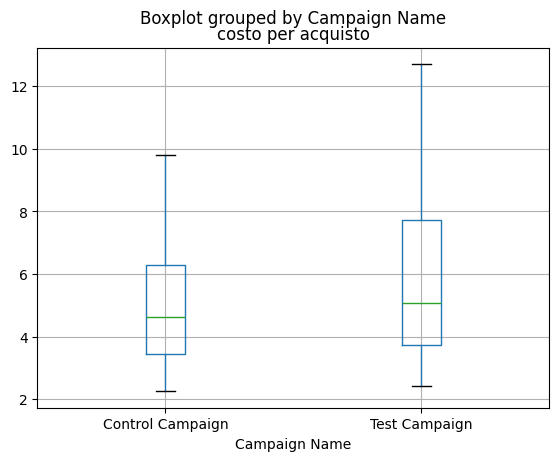

                      mean       std
Campaign Name                       
Control Campaign  0.114772  0.068383
Test Campaign     0.092312  0.044490
29 30
TtestResult(statistic=np.float64(1.4899942228754453), pvalue=np.float64(0.14278642437865938), df=np.float64(47.86427383089159))


In [11]:
import matplotlib.pyplot as plt

df.boxplot(column="costo per acquisto", by="Campaign Name")
plt.show()

df["conversione"] = df["# of Purchase"] / df["# of Website Clicks"]
print(df.groupby("Campaign Name")["conversione"].agg(["mean", "std"]))
conv_controllo = df[df["Campaign Name"] == "Control Campaign"]["conversione"]
conv_test = df[df["Campaign Name"] == "Test Campaign"]["conversione"]

print(len(conv_controllo), len(conv_test))
print(stats.ttest_ind(conv_controllo, conv_test, equal_var=False))

“Costo medio per acquisto: controllo 5,05 $, test 5,90 $. Test di Welch: p = 0,19, differenza non significativa. Prossimo passo: boxplot.”